# 7. Число пространственных гармоник при обучении PINN

Ускоряет ли уменьшение числа входных гармоник обучение односолитонного решения на интервале от 0 до 4 при сопоставимой ошибке комплексного поля?

В серии от 26 ноября варианты с 1, 2 и 6 гармониками запускались последовательно на первой RTX 4090 параллельно с другим расчётом. Для ориентира добавлен запуск с 4 гармониками от 21 ноября. Сеть получает пары sin(k theta), cos(k theta) для k от 1 до выбранного максимума. Во всех случаях использованы 4 скрытых слоя ширины 64, 32 768 внутренних точек, равномерная выборка с обновлением каждые 100 шагов, seed 42 и 500 000 шагов Adam.

In [1]:
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from lle.analysis.fields import relative_l2_error
from lle.runs.runs import get_run
from lle.storage import load_evolution

import json
import yaml

run_ids = {
    1: "2026-11-26_14-58-01_248907",
    2: "2026-11-26_16-25-48_758121",
    4: "2026-11-21_07-48-25_600230",
    6: "2026-11-26_18-01-36_832947",
}
reference_id = "2026-11-10_07-44-12_914080"
reference_path = get_run(reference_id).path
reference = load_evolution(reference_path)
reference_config = yaml.safe_load((reference_path / "parameters.yaml").read_text())
errors, minutes, global_errors, losses = {}, {}, {}, {}
common_config = None
for count, run_id in run_ids.items():
    path = get_run(run_id).path
    config = yaml.safe_load((path / "parameters.yaml").read_text())
    metadata = json.loads((path / "metadata.json").read_text())
    assert metadata["status"] == "complete"
    assert metadata["runtime"]["device_name"] == "NVIDIA GeForce RTX 4090"
    assert config["network"].pop("spatial_harmonics") == count
    assert all(config[key] == reference_config[key] for key in ("initial", "equation"))
    if common_config is None:
        common_config = config
    assert config == common_config
    field = load_evolution(path)
    np.testing.assert_array_equal(field.theta, reference.theta)
    np.testing.assert_allclose(field.times, reference.times, atol=1e-10, rtol=0)
    errors[count] = 100 * relative_l2_error(field.values, reference.values)
    global_errors[count] = 100 * np.linalg.norm(field.values - reference.values) / np.linalg.norm(reference.values)
    elapsed = datetime.fromisoformat(metadata["finished_utc"]) - datetime.fromisoformat(metadata["started_utc"])
    minutes[count] = elapsed.total_seconds() / 60
    losses[count] = np.genfromtxt(path / "losses.csv", delimiter=",", names=True)
    np.testing.assert_array_equal(losses[count]["step"], np.arange(0, 500_001, 100))

## Точность и длительность

Эталон SSFM рассчитан с шагом 0.0005. Сравниваем комплексные поля на общей сетке из 512 пространственных точек и 401 кадра через 0.01. Ошибка на всей сетке равна отношению L2-норм разности полей и эталона. Для ошибки в отдельном кадре обе нормы берутся только по пространству. Длительность включает весь запуск от старта до завершения по метаданным.

In [2]:
rows = [
    "| Гармоники | На всей сетке, % | Максимум по кадрам, % | t максимума | При t=4, % | Время, мин |",
    "|---:|---:|---:|---:|---:|---:|",
]
for count, error in errors.items():
    peak = error.argmax()
    rows.append(f"| {count} | {global_errors[count]:.3f} | {error[peak]:.3f} | "
                f"{reference.times[peak]:.2f} | {error[-1]:.3f} | {minutes[count]:.1f} |")
display(Markdown("\n".join(rows)))

| Гармоники | На всей сетке, % | Максимум по кадрам, % | t максимума | При t=4, % | Время, мин |
|---:|---:|---:|---:|---:|---:|
| 1 | 1.192 | 1.859 | 3.68 | 1.007 | 87.8 |
| 2 | 1.139 | 1.694 | 2.54 | 0.962 | 95.8 |
| 4 | 1.315 | 1.953 | 1.58 | 1.155 | 79.4 |
| 6 | 1.195 | 1.787 | 1.58 | 1.006 | 99.5 |

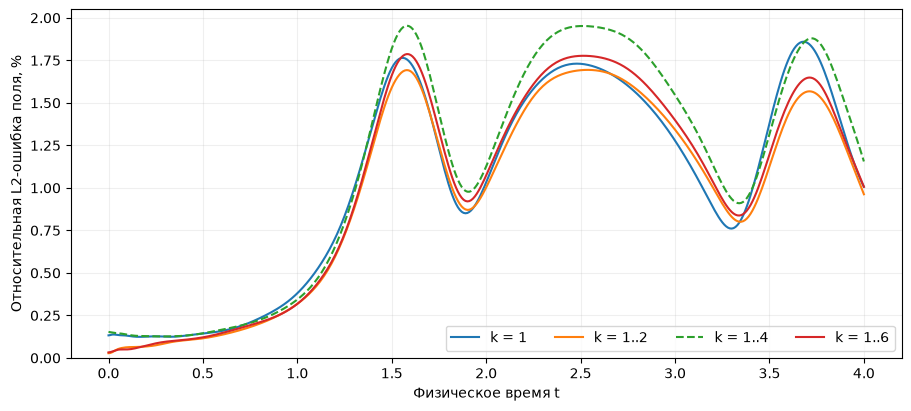

In [3]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
for count, error in errors.items():
    ax.plot(reference.times, error, label=f"k = 1..{count}" if count > 1 else "k = 1",
            linestyle="--" if count == 4 else "-")
ax.set(xlabel="Физическое время t", ylabel="Относительная L2-ошибка поля, %", ylim=(0, None))
ax.legend(ncol=4)
ax.grid(alpha=0.2)
plt.show()

## Ход оптимизации

Поля сохранены для конечных моделей. Журнал обучения позволяет проследить невязку уравнения по шагам. Время достижения заданной ошибки относительно SSFM по этому журналу определить нельзя.

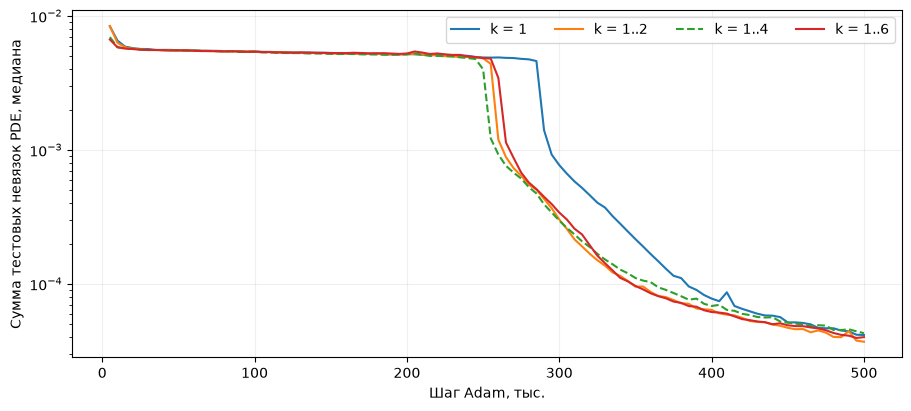

In [4]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
for count, history in losses.items():
    residual = history["test_pde_u"] + history["test_pde_v"]
    # Медиана по интервалам в 5 тысяч шагов сглаживает кратковременные скачки.
    median = np.median(residual[1:].reshape(-1, 50), axis=1)
    ax.semilogy(history["step"][50::50] / 1000, median, label=f"k = 1..{count}" if count > 1 else "k = 1",
                linestyle="--" if count == 4 else "-")
ax.set(xlabel="Шаг Adam, тыс.", ylabel="Сумма тестовых невязок PDE, медиана")
ax.grid(alpha=0.2)
ax.legend(ncol=4)
plt.show()

## Выводы

- **Для быстрого расчёта на T=4 достаточно одной входной гармоники.** Это самый короткий запуск новой серии. По сравнению с шестью гармониками он занял на 11.8 минуты меньше (около 12%), при практически одинаковой ошибке на всей сетке (около 1.19%). Максимальная ошибка по кадрам при одной гармонике немного выше.
- **Две гармоники дали самую низкую ошибку** как на всей сетке, так и в худшем кадре. Переход от одной гармоники к двум стоил 8 минут и снизил общую ошибку примерно на 0.053 процентного пункта. Шесть гармоник при этом бюджете преимуществ перед двумя не показали.
- Архивный запуск с четырьмя гармониками завершился быстрее всех. Он выполнен в другой день и на другой ревизии кода. Серверные метаданные также указывают на локальные изменения. Загрузка GPU во время запусков могла различаться, поэтому выигрыш во времени относительно архивного запуска по этой серии оценить нельзя.
- Каждый вариант обучался один раз. Различия в точности относятся к этому начальному условию, seed и бюджету шагов.